# Blur

Quantum Blur turns an image into a single quantum state, rotates every qubit once, and measures the state back into pixels. One gate moves amplitude between pixels that can be far apart, so instead of soft focus you get echoes and interference that no convolution kernel produces.

## Setup

In [1]:
import getpass
import os

from moth_atlas import Atlas

if not os.environ.get("MOTH_API_KEY"):
    os.environ["MOTH_API_KEY"] = getpass.getpass("Atlas API key")

client = Atlas()  # reads MOTH_API_KEY

Atlas API key ········


In [2]:
import base64
from IPython.display import HTML, display

def row(images, width=170):
    """Show {label: image bytes} side by side."""
    cells = "".join(f'<td align="center"><img src="data:image/png;base64,{base64.b64encode(data).decode()}" width="{width}"><br>{label}</td>'
                    for label, data in images.items())
    display(HTML(f"<table><tr>{cells}</tr></table>"))  # a table: GitHub's renderer strips inline styles

## Try it

Point `image` at your own file, or keep the sample cat beside this notebook. `run` uploads it, submits the job and waits; `job.download()` saves the result.

blur-v1 job 94d6ad59 submitted
blur-v1 job 94d6ad59 completed (4s)


input,blurred

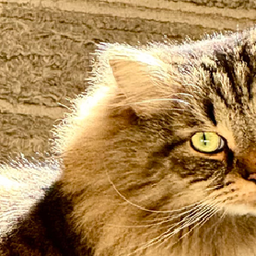
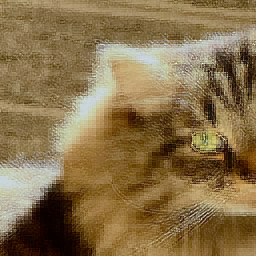

In [3]:
job = client.jobs.run(
    engine="blur-v1",
    params={
        "strength": 0.5,
        "style": "rx",
        "reach": 0,
    },
    files={
        "image": "cat.png",
    },
)
row({"input": open("cat.png", "rb").read(), "blurred": job.output_bytes()}, width=300)

## Parameters

What to expect from each:

- `strength` (0 to 1): scales every rotation; 0 returns the input unchanged, the echoes grow up to 1.
- `style`: `rx` spreads echoes across the image, `ry` concentrates them on edges.
- `reach` (0 to 1): 0 weights each angle by local brightness, 1 turns every qubit equally, so echoes land anywhere.
- `size` and `downscale`: a region over the pixel budget is downscaled (`true`) or tiled (`false`).
- `mask` (input file): blurs each region of the mask on its own and blends by its intensity; `mask_bin_size` and `mask_min_region` clean it up.

The engine's full definition:

In [4]:
client.engines.get("blur-v1")  # its description, params, input and output files

**blur-v1** · Quantum Blur · v1.2.0 · 1 credit per run

Apply a quantum blur algorithm to the image.

**Params**

| param | type | default | range | description |
|---|---|---|---|---|
| backend | string \| null | None |   | Device name for `emu`/`qpu` (e.g. `fez`, `marrakesh`, `garnet`). `emu` resolves it to the device's … |
| downscale | boolean | True |   | Strategy used when a mask region is larger than the maximum number of qubits allows: - `true` — the… |
| execution_mode | 'sim' \| 'emu' \| 'qpu' \| 'local' | 'sim' |   | Where the quantum blur runs, through moth_backbone: - `sim` - exact statevector simulation (default… |
| io | object \| null | None |   | Standard moth_backbone execution block: mode (sim \| emu \| qpu), provider (ibm \| iqm), backend, shot… |
| machine | string \| null | None |   | Platform shorthand for where to run, one key instead of execution_mode / provider / backend: `aer` … |
| mask_bin_size | number \| null | 4 | >= 0, <= 100 | Mask quantisation step as a percentage of 255 (0–100). Pixel values below this threshold are treate… |
| mask_min_region | integer \| null | 16 | >= 1 | Minimum mask region size in pixels. Connected components smaller than this are discarded after quan… |
| provider | 'aer' \| 'ibm' \| 'iqm' | 'aer' |   | Provider for `emu`/`qpu`: `ibm` or `iqm`. Ignored for `sim`/`local` (always aer). |
| reach | number | 0 | >= 0, <= 1 | Controls how far from its original position a pixel can be affected by the blur: - `0` — fully loca… |
| shots | integer | 4096 | >= 1, <= 100000 | Measurements per circuit on `emu`/`qpu` - the blur is estimated from them, so more shots = less noi… |
| size | integer | 1024 | >= 8, <= 1024 | Pixel budget per blur pass: a region up to `size × size` pixels is blurred in a single pass. Intern… |
| store_results | boolean | True |   | Store every executed circuit (result, fidelity, calibration) through moth_backbone. |
| strength | number | 0.5 | >= 0, <= 1 | Strength of the effect, which controls the rotation applied to each qubit: - `0` — the image is lef… |
| style | 'rx' \| 'ry' | 'rx' |   | Quantum gate used to apply the effect: - `rx` — rotation around the x-axis of the Bloch sphere. - `… |

**Input files**

| slot | required | types | description |
|---|---|---|---|
| image | required | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The image of your choice. The blur effect is applied RGB pixel values only, not the alpha channel. … |
| mask | optional | image/png, image/jpeg, image/webp, image/tiff, image/bmp | Optional mask controlling where the effect is applied, on a per-pixel basis. Must match the size of… |

**Returns files (job.outputs)**

| slot | types | description |
|---|---|---|
| result | image/png, image/jpeg, image/webp, image/tiff, image/bmp | The processed image. |

**Example**

```python
job = client.jobs.run(
    engine="blur-v1",
    params={
        "downscale": True,
        "execution_mode": "sim",
        "mask_bin_size": 4,
        "mask_min_region": 16,
        "provider": "aer",
        "reach": 0,
        "shots": 4096,
        "size": 1024,
        "store_results": True,
        "strength": 0.5,
        "style": "rx",
    },
    files={
        "image": "image.png",
    },
)
```

Full docs: `engine.description_md`

## How it works

Quantum Blur has no convolution kernel. The image is encoded as a single quantum state, each qubit is rotated once, and the state is measured back into pixels. Because a single gate redistributes amplitude between pixels that may be far apart on the canvas, the output shows interference patterns rather than soft focus.

**Encode.** Pixel $(x,y)$ with brightness $h$ maps to a basis state, Gray-coded per axis:

$$|\psi\rangle \;\propto\; \sum_{x,y} \sqrt{h(x,y)}\;|g(x)\,g(y)\rangle, \qquad n = \lceil\log_2 W\rceil + \lceil\log_2 H\rceil \text{ qubits}$$

**Rotate.** One `rx` (or `ry`) per qubit, with an image-dependent angle:

$$\theta_q = \pi\,\xi\,\big[(1-\text{reach})\, r_q + \text{reach}\big], \qquad \xi = \text{strength} \;(\texttt{rx})\;\text{ or }\;\text{strength}^2 \;(\texttt{ry})$$

where $r_q$ is the normalised brightness on neighbour pairs whose labels differ in qubit $q$.

**Read back.** $h' = |\text{amp}|^2 / \max$, rescaled to the channel's original maximum. With a mask $m$, the output is $m\cdot\text{blurred} + (1-m)\cdot\text{original}$.

## Experiments

Each experiment changes one parameter and keeps the others fixed, and runs one job per value.

### Strength

$\xi$ scales every angle. At 0 the round trip is exact; the echoes grow with it up to the limit of 1 (past that the rotations would start to undo themselves, which is why the engine stops there).

strength=0.0
strength=0.25
strength=0.5
strength=0.75
strength=1.0


strength 0.0,strength 0.25,strength 0.5,strength 0.75,strength 1.0

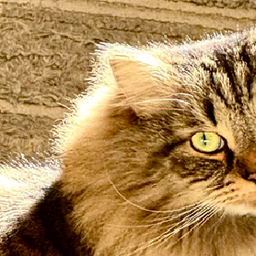
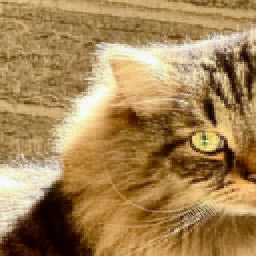
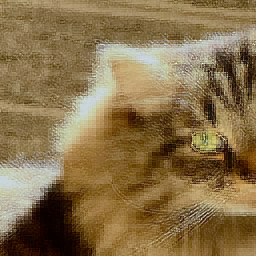
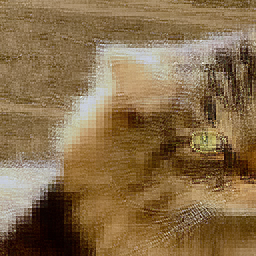
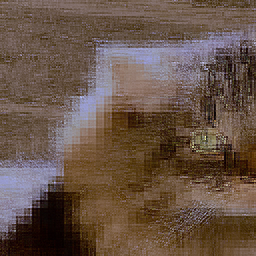

In [5]:
outputs = {}
for strength in (0.0, 0.25, 0.5, 0.75, 1.0):
    print(f"strength={strength}")
    job = client.jobs.run(engine="blur-v1", params={"strength": strength}, files={"image": "cat.png"}, quiet=True)
    outputs[f"strength {strength}"] = job.output_bytes()
row(outputs)

### Reach and style

`reach` lifts the locality: at 0 the angle on each qubit is weighted by the brightness it separates, at 1 every qubit turns by the same $\pi\xi$ and echoes land anywhere on the canvas. `ry` keeps the same angles (with $\xi = \text{strength}^2$) but its interference terms cancel instead of spreading, so weight collects at a few pixels and smooth areas go dark.

style=rx reach=0.0
style=rx reach=0.5
style=rx reach=1.0
style=ry reach=0.0
style=ry reach=0.5
style=ry reach=1.0


rx · reach 0.0,rx · reach 0.5,rx · reach 1.0,ry · reach 0.0,ry · reach 0.5,ry · reach 1.0

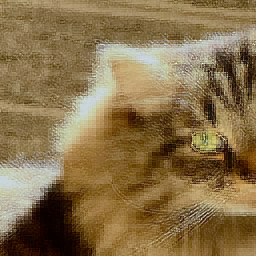
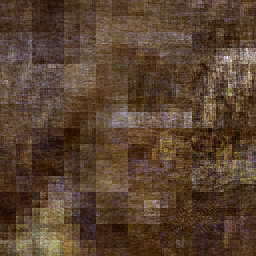
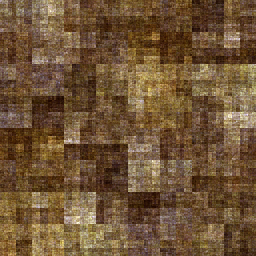
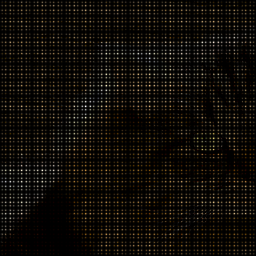
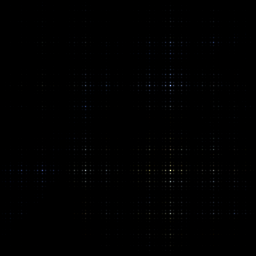
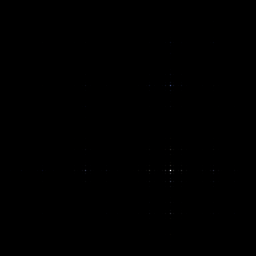

In [6]:
outputs = {}
for style in ("rx", "ry"):
    for reach in (0.0, 0.5, 1.0):
        print(f"style={style} reach={reach}")
        job = client.jobs.run(engine="blur-v1", params={"style": style, "reach": reach}, files={"image": "cat.png"}, quiet=True)
        outputs[f"{style} · reach {reach}"] = job.output_bytes()
row(outputs)

### Mask

A feathered disc: 1 inside, a soft ramp, 0 outside. The engine blurs the disc's bounding box as its own state and blends by mask intensity, so pixels outside the mask must come back untouched and the edge must be a gradient, not a seam.

In [7]:
import io
from PIL import Image, ImageDraw, ImageFilter

# A feathered disc in the middle of the image: white blurs, black stays untouched.
w, h = Image.open("cat.png").size
r = 0.3 * min(w, h)
mask = Image.new("L", (w, h), 0)
ImageDraw.Draw(mask).ellipse((w / 2 - r, h / 2 - r, w / 2 + r, h / 2 + r), fill=255)
buf = io.BytesIO()
mask.filter(ImageFilter.GaussianBlur(r / 6)).save(buf, "PNG")
mask_png = buf.getvalue()

blur-v1 job 9949738b submitted
blur-v1 job 9949738b completed (3s)


input,mask,masked

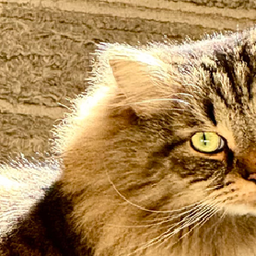
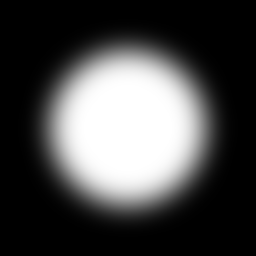
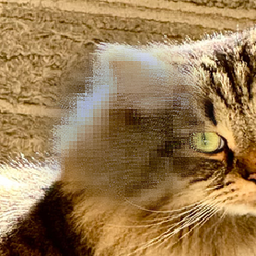

In [8]:
job = client.jobs.run(engine="blur-v1", params={"strength": 0.8}, files={"image": "cat.png", "mask": ("mask.png", mask_png, "image/png")})
row({"input": open("cat.png", "rb").read(), "mask": mask_png, "masked": job.output_bytes()})

## Questions

**Is this running on real quantum hardware?**

No. Blur runs on a classical statevector simulator, so jobs run on CPU or GPU. The circuits and the interference are real; the execution is emulated. That keeps results exact and repeatable with no shot noise. Real hardware would need very high connectivity and enough shots to rebuild the whole state, which is not yet practical at image scale.

**Why does it look different from a classical blur?**

A classical blur averages each pixel with a fixed neighbourhood. Blur has no kernel: one rotation per qubit mixes amplitude between every pixel at once, so the shape of the smear comes from the circuit, not a window. That is where the echo-like, non-local look comes from.

**How does image size affect run time?**

Qubits grow with the log of the image size (16 for 256 × 256, 20 for 1024 × 1024), but simulator memory and time grow exponentially with qubits. Regions over the qubit budget are downscaled or tiled, depending on `downscale`.

**What happens with colour images?**

Each of red, green and blue is blurred as its own state and the channels are recombined. The same technique was used on ILĀ's [Recurse album](https://infinite.mothquantum.com).

**Why does strength 0 round-trip exactly?**

Encoding normalises the state, which throws away absolute brightness. The engine keeps each channel's original maximum and restores it on read-back, so with no rotation the output equals the input.

**Where can I read more?**

The open-source [QuantumBlur repository](https://github.com/qiskit-community/QuantumBlur) walks through the underlying library.